# 10 — Portfolio Optimization

**Goal:** trace the efficient frontier and identify the minimum-variance and
maximum-Sharpe portfolios for this asset universe, using full-history
mean/covariance (an exploratory "what should I hold today" analysis — see
the module docstring in `src/portfolio/optimization.py` for why this is not
a valid backtest by itself).

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)

np.random.seed(42)

from notebooks.nb_utils import fetch_price_panel

TICKERS = ["AAPL", "MSFT", "GLD", "BND", "SPY"]
START = "2019-01-01"

price_panel, used_synthetic = fetch_price_panel(TICKERS, START)
returns_panel = price_panel.pct_change().dropna()
print(f"Loaded {price_panel.shape[0]} rows x {price_panel.shape[1]} tickers. Synthetic data: {used_synthetic}")
price_panel.tail()

Failed to get ticker 'MSFT' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


Failed to get ticker 'AAPL' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


... (7 outputs left out)

['MSFT', 'AAPL']: JSONDecodeError('Expecting value: line 1 column 1 (char 0)')


['BND', 'GLD', 'SPY']: possibly delisted; no timezone found


[info] Live data unavailable (KeyError); using synthetic demo data instead.
Loaded 2004 rows x 5 tickers. Synthetic data: True


,AAPL,MSFT,GLD,BND,SPY
2026-08-31,229.681016,128.274867,119.914845,364.746718,107.728124
2026-09-01,227.093540,128.294744,120.000708,372.445526,106.711406
2026-09-02,229.155329,127.875189,121.085078,365.765614,106.991434
2026-09-03,232.958620,125.652809,122.697759,374.610608,107.656847
2026-09-04,232.705684,125.622649,120.900524,369.667262,106.661264


In [2]:
from src.portfolio.optimization import (
    minimum_variance_portfolio, maximum_sharpe_portfolio,
    efficient_frontier, random_feasible_portfolios,
)
from src.config import CONFIG

mean_returns = returns_panel.mean()
cov_matrix = returns_panel.cov()
rf_daily = CONFIG["risk"]["risk_free_rate_annual"] / 252
max_weight = 0.5

min_var = minimum_variance_portfolio(mean_returns, cov_matrix, max_weight=max_weight)
max_sharpe = maximum_sharpe_portfolio(mean_returns, cov_matrix, rf_daily, max_weight=max_weight)
frontier = efficient_frontier(mean_returns, cov_matrix, max_weight=max_weight, risk_free_rate=rf_daily)
random_portfolios = random_feasible_portfolios(mean_returns, cov_matrix, n_portfolios=3000, risk_free_rate=rf_daily)

print(f"Min-variance:  return={min_var.expected_return*252:.2%}  vol={min_var.volatility*np.sqrt(252):.2%}")
print(f"Max-Sharpe:    return={max_sharpe.expected_return*252:.2%}  vol={max_sharpe.volatility*np.sqrt(252):.2%}  Sharpe={max_sharpe.sharpe_ratio*np.sqrt(252):.2f}")

Min-variance:  return=5.76%  vol=8.97%
Max-Sharpe:    return=14.42%  vol=15.81%  Sharpe=0.79


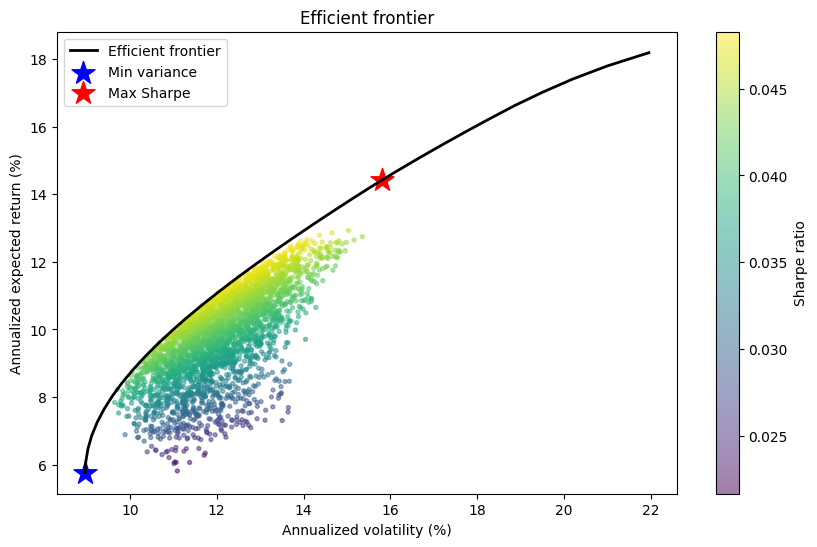

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(
    random_portfolios["volatility"] * np.sqrt(252) * 100,
    random_portfolios["expected_return"] * 252 * 100,
    c=random_portfolios["sharpe_ratio"], cmap="viridis", s=8, alpha=0.5,
)
ax.plot(frontier["volatility"] * np.sqrt(252) * 100, frontier["expected_return"] * 252 * 100, color="black", linewidth=2, label="Efficient frontier")
ax.scatter([min_var.volatility * np.sqrt(252) * 100], [min_var.expected_return * 252 * 100], color="blue", marker="*", s=300, label="Min variance")
ax.scatter([max_sharpe.volatility * np.sqrt(252) * 100], [max_sharpe.expected_return * 252 * 100], color="red", marker="*", s=300, label="Max Sharpe")
plt.colorbar(sc, label="Sharpe ratio")
ax.set_xlabel("Annualized volatility (%)")
ax.set_ylabel("Annualized expected return (%)")
ax.legend()
ax.set_title("Efficient frontier")
plt.show()

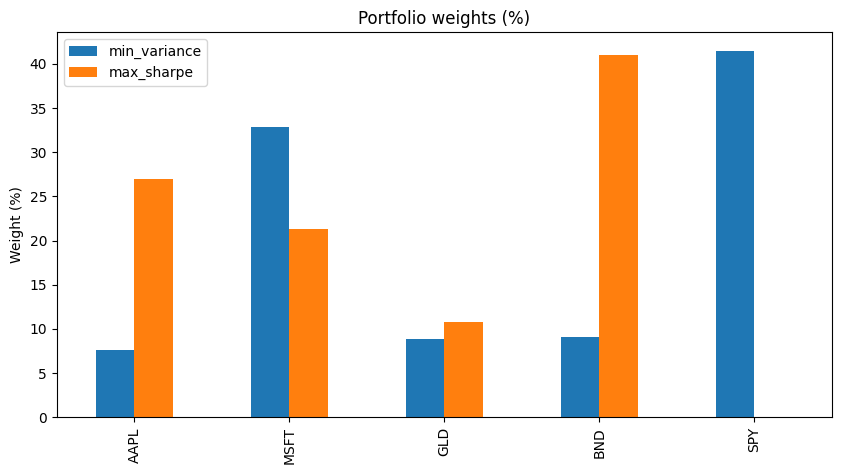

In [4]:
weights_table = pd.DataFrame({"min_variance": min_var.weights, "max_sharpe": max_sharpe.weights})
(weights_table * 100).round(1).plot(kind="bar", title="Portfolio weights (%)")
plt.ylabel("Weight (%)")
plt.show()

## Takeaways

- The minimum-variance portfolio favors the lowest-volatility, least-correlated assets regardless of expected return; the maximum-Sharpe portfolio balances return against risk.
- Both respect the `max_weight` cap from `config.yaml`, preventing an unrealistic all-in-one-asset solution.
- Continue to **11 — ML Model Development** to see whether a trained model can add predictive value beyond these static allocations.